# 옷장패션 데이터 정제 보고서



## 0. 환경 준비

In [1]:
# ─────────────────────────────────────────────
# 환경 준비 — 라이브러리 + 한글 폰트 + 시드 고정
# ─────────────────────────────────────────────
# 필요 시 아래 주석을 해제해 설치하세요.
!pip install numpy pandas matplotlib seaborn missingno -q

import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno   # 결측 패턴 시각화 전용 라이브러리 (Part 3에서 사용)

warnings.filterwarnings("ignore")

# 재현성: 같은 난수를 항상 같게 만들어 결과가 매번 동일하도록 고정합니다.
np.random.seed(42)

# seaborn 스타일은 폰트 설정보다 먼저 (나중에 쓰면 한글 폰트가 초기화됨)
sns.set_style("whitegrid")

# 한글 폰트 설정 (운영체제별 분기)
system = platform.system()
if system == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
elif system == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
else:
    plt.rcParams["font.family"] = "DejaVu Sans"

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 5)

print("준비 완료! 라이브러리 버전을 확인합니다.")
print("numpy :", np.__version__)
print("pandas:", pd.__version__)

준비 완료! 라이브러리 버전을 확인합니다.
numpy : 2.5.4
pandas: 3.0.6


In [2]:
# 5종 세트 ② — 열별 결측 비율(%) — '많고 적음'을 직관적으로
def missing_summary(df):
    s = df.isnull().sum()
    p = (df.isnull().mean() * 100).round(2)
    out = pd.DataFrame({"missing": s, "missing_pct(%)": p})
    return out[out["missing"] > 0].sort_values("missing", ascending=False)

# IQR을 재사용 가능한 함수로 만들기 — 분석가의 일상 도구
def detect_outliers_iqr(series, k=1.5):
    '''IQR 방법으로 이상치 마스크와 경계를 반환합니다.

    Parameters
    ----------
    series : pd.Series  — 수치형 시리즈
    k      : float      — 경계 폭의 IQR 배수 (기본 1.5, 더 엄격하게 보려면 3)

    Returns
    -------
    mask   : pd.Series(bool)  — 이상치 위치 (True)
    bounds : (lower, upper)   — 경계값
    '''
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - k * iqr
    upper = q3 + k * iqr
    mask = (series < lower) | (series > upper)
    return mask, (lower, upper), (q1, q3)

## 1. 데이터 개요
- 행/열: 1,500 × 8
- 주요 컬럼: order_id, customer_age, category, channel, price, quantity, amount, return_amount


In [3]:
# 새 데이터셋 — '옷장패션' 주문 (가상)
np.random.seed(11)
n = 1500

partner = pd.DataFrame({
    "order_id": [f"K{str(i).zfill(5)}" for i in range(1, n + 1)],
    "customer_age": np.random.normal(33, 8, n).round().astype(int),
    "category": np.random.choice(["상의", "하의", "신발", "액세서리"], n, p=[0.35, 0.3, 0.2, 0.15]),
    "channel": np.random.choice(["web", "app"], n, p=[0.4, 0.6]),
    "price": np.random.choice([15900, 29900, 49900, 79900, 129900], n),
    "quantity": np.random.choice([1, 1, 1, 2, 2, 3], n),
})
partner["amount"] = partner["price"] * partner["quantity"]
partner["return_amount"] = np.where(
    np.random.rand(n) < 0.07, partner["amount"] * np.random.uniform(0.5, 1.0, n), 0
).round(0)

# 오염 심기
# (a) 나이 이상치 — 입력 실수(0, 999)
partner.loc[partner.sample(3, random_state=1).index, "customer_age"] = 999
partner.loc[partner.sample(2, random_state=2).index, "customer_age"] = 0

# (b) amount 결측 — app 채널에 더 자주 (MAR 시그널)
app = partner["channel"] == "app"
partner.loc[partner[app].sample(frac=0.05, random_state=3).index, "amount"] = np.nan
partner.loc[partner[~app].sample(frac=0.01, random_state=4).index, "amount"] = np.nan

# (c) return_amount 결측은 그대로 (0=환불없음)이라 결측 아님. 단, '관찰 안 됨'을 의도적으로 표현하기 위해
#     price 결측 5건 추가(접속 시점 가격이 누락된 사례)
partner.loc[partner.sample(5, random_state=5).index, "price"] = np.nan

# (d) quantity 이상치(단일 소비자 200개)
partner.loc[partner.sample(1, random_state=6).index, "quantity"] = 200

# (e) amount 극단값(50,000,000짜리 한 건 — '도매 의심')
partner.loc[partner.sample(1, random_state=7).index, "amount"] = 50_000_000

print("옷장패션 데이터 준비 완료:", partner.shape)
partner.head()

옷장패션 데이터 준비 완료: (1500, 8)


,order_id,customer_age,category,channel,price,quantity,amount,return_amount
0,K00001,47,신발,app,29900.0,2,59800.0,45445.0
1,K00002,31,상의,app,129900.0,3,389700.0,0.0
2,K00003,29,상의,web,49900.0,2,99800.0,0.0
3,K00004,12,상의,web,49900.0,3,149700.0,0.0
4,K00005,33,하의,app,129900.0,1,129900.0,0.0


## 2. 진단 결과
- 결측: amount 3.40%(51건), price 0.33%(5건), 나머지 컬럼은 결측 없음
  - 행별 결측은 최대 1개 → 한 행에 결측이 몰린 경우 없음
- 이상치(IQR): customer_age(999 3건·0 2건 포함, 18건), quantity(200, 1건), amount(50,000,000 포함, 145건)
- 의심되는 결측 유형
  - amount: app 채널에 쏠림 → **MAR** (전체 app 비중 61% vs amount 결측 행의 app 비중 88%)
  - price: 5건이 채널(app 2·web 3)·카테고리에 흩어져 있고 특정 패턴 없음 → **MCAR**
- 정합성: amount ≠ price × quantity 인 행 2건 (quantity 200 행, amount 50,000,000 행)
- 참고
  - customer_age 18건에는 999·0 같은 입력 오류뿐 아니라 경계(12.6~53.6) 밖의 정상 고객도 섞여 있음
  - amount 145건 중 명백한 오류는 50,000,000원 1건이고, 나머지는 고가 상품을 여러 개 산 정상 주문
  - return_amount 122건은 값 대부분이 0이라 IQR이 0이 되어 반품 건이 모두 잡힌 것 → 이상치로 보지 않음

> 근거: 아래 진단 코드 셀(기본 정보 / 결측 진단 / 결측 5종 세트 / IQR 이상치 / 도메인 오류값 확인)의 출력 참고


In [4]:
# 시나리오 1 — 진단
print("shape:", partner.shape)
partner.info()
display(partner.describe())

shape: (1500, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       1500 non-null   str    
 1   customer_age   1500 non-null   int64  
 2   category       1500 non-null   str    
 3   channel        1500 non-null   str    
 4   price          1495 non-null   float64
 5   quantity       1500 non-null   int64  
 6   amount         1449 non-null   float64
 7   return_amount  1500 non-null   float64
dtypes: float64(3), int64(2), str(3)
memory usage: 93.9 KB


,customer_age,price,quantity,amount,return_amount
count,1500.000000,1495.000000,1500.000000,1.449000e+03,1500.000000
mean,34.903333,60960.869565,1.789333,1.350475e+05,6381.010000
std,43.936525,40275.103681,5.173406,1.313695e+06,28315.037316
min,0.000000,15900.000000,1.000000,1.590000e+04,0.000000
25%,28.000000,29900.000000,1.000000,4.770000e+04,0.000000
50%,33.000000,49900.000000,2.000000,7.990000e+04,0.000000
75%,38.250000,79900.000000,2.000000,1.299000e+05,0.000000
max,999.000000,129900.000000,200.000000,5.000000e+07,322778.000000


In [5]:
# 결측 진단
print("[열별 결측]")
display(missing_summary(partner))

# 결측이 채널과 관련 있는지 (MAR 신호 검사)
amt_null = partner[partner["amount"].isnull()]
print("\n[amount 결측 행의 채널 분포]")
print(amt_null["channel"].value_counts(normalize=True).round(2))
print("\n[전체 채널 분포]")
print(partner["channel"].value_counts(normalize=True).round(2))

[열별 결측]


,missing,missing_pct(%)
amount,51,3.40
price,5,0.33



[amount 결측 행의 채널 분포]
channel
app    0.88
web    0.12
Name: proportion, dtype: float64

[전체 채널 분포]
channel
app    0.61
web    0.39
Name: proportion, dtype: float64


[행별 결측 개수 분포]
0    1444
1      56
Name: count, dtype: int64

[price 결측 행]


,order_id,customer_age,category,channel,price,quantity,amount,return_amount
656,K00657,26,신발,app,NaN,3,149700.0,0.0
669,K00670,43,하의,web,NaN,1,79900.0,0.0
822,K00823,52,하의,web,NaN,1,15900.0,0.0
931,K00932,39,액세서리,web,NaN,1,129900.0,100018.0
1187,K01188,12,상의,app,NaN,2,59800.0,0.0


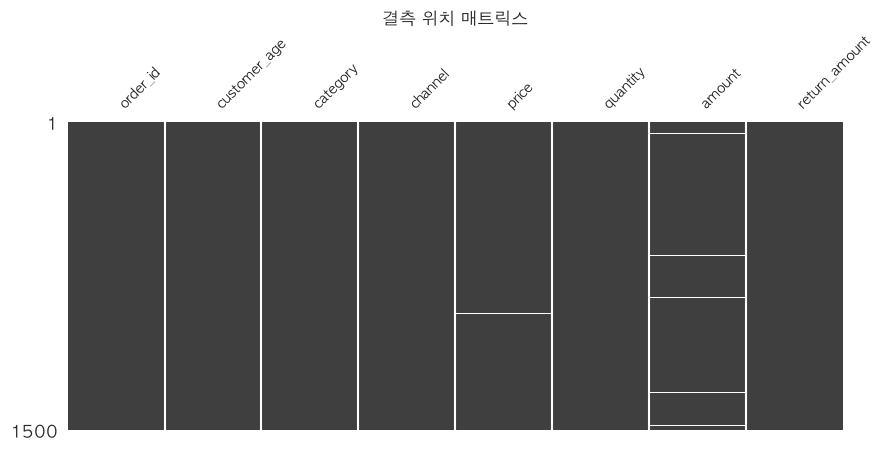

In [6]:
# 결측 진단 5종 세트 — ①열별 수 ②열별 비율은 위 missing_summary로 확인
# ③ 행별 결측 개수 — 한 행에 결측이 몰려 있는지
row_missing = partner.isnull().sum(axis=1)
print("[행별 결측 개수 분포]")
print(row_missing.value_counts().sort_index())

# ④ 특정 열 결측 행 — price 결측 행을 직접 확인
print("\n[price 결측 행]")
display(partner[partner["price"].isnull()])

# ⑤ 결측 히트맵 — 결측 위치 패턴 시각화
ax = msno.matrix(partner, figsize=(10, 4), fontsize=10, sparkline=False)
ax.set_title("결측 위치 매트릭스")
plt.show()

In [7]:
# IQR 이상치 — 수치형 컬럼 일괄 점검
num_cols = ["customer_age", "price", "quantity", "amount", "return_amount"]
print("[IQR 기준 이상치 개수]")
for c in num_cols:
    mask, (lo, up), _ = detect_outliers_iqr(partner[c].dropna())
    print(f"  {c:15s}  하한={lo:>12.1f}  상한={up:>12.1f}  이상치={mask.sum()}건")

[IQR 기준 이상치 개수]
  customer_age     하한=        12.6  상한=        53.6  이상치=18건
  price            하한=    -45100.0  상한=    154900.0  이상치=0건
  quantity         하한=        -0.5  상한=         3.5  이상치=1건
  amount           하한=    -75600.0  상한=    253200.0  이상치=145건
  return_amount    하한=         0.0  상한=         0.0  이상치=122건


In [8]:
# 도메인 기준 오류값 직접 확인 — IQR 건수에는 정상 고객도 섞여 있으므로 따로 셉니다.
print("customer_age = 999 :", (partner["customer_age"] == 999).sum(), "건")
print("customer_age = 0   :", (partner["customer_age"] == 0).sum(), "건")
print("quantity = 200     :", (partner["quantity"] == 200).sum(), "건")
print("amount = 50,000,000:", (partner["amount"] == 50_000_000).sum(), "건")

# 정합성: amount = price × quantity 가 맞지 않는 행
valid = partner.dropna(subset=["price", "amount"])
mismatch = valid[valid["amount"] != valid["price"] * valid["quantity"]]
print("\n[amount ≠ price × quantity 행]:", len(mismatch), "건")
display(mismatch)

customer_age = 999 : 3 건
customer_age = 0   : 2 건
quantity = 200     : 1 건
amount = 50,000,000: 1 건

[amount ≠ price × quantity 행]: 2 건


,order_id,customer_age,category,channel,price,quantity,amount,return_amount
24,K00025,38,신발,app,29900.0,200,89700.0,0.0
547,K00548,33,신발,app,49900.0,1,50000000.0,0.0


## 3. 처리 결정과 근거
| 컬럼·이슈 | 결정 | 근거(한 줄) | 한계(한 줄) |
| --- | --- | --- | --- |
| `amount` 결측 | 채널별 중앙값 대체 | 결측 행의 app 비중 88%(전체 61%) → MAR 가설에 부합 | 채널 외 다른 원인은 검토 안 함 |
| `price` 결측 | 카테고리별 중앙값 대체 | 비율 0.33%(5건)로 적음, 카테고리별 가격대 보존 | 표본이 적어 카테고리 통계가 불안정 |
| `customer_age = 999, 0` | NaN 표시 → 중앙값 대체 | 물리적 불가능 — 입력 실수 추정 | 외부 인증 데이터 없음 |
| `quantity = 200` | NaN 표시 → 중앙값 대체 | 일반 소비자 도메인 밖의 값 | 도매 가능 고객이면 제거가 손실 |
| `amount = 50,000,000` | 유지 + `amount_outlier` 플래그 | 1건의 비즈니스적 가능성 보존 | 도매면 별도 분석 필요 |
| `return_amount` IQR 122건 | 처리 안 함 | 0 = 반품 없음, IQR이 0이라 반품 건이 전부 잡힌 것 | - |


In [9]:
# 시나리오 3 — 처리 코드
partner_clean = partner.copy()

# 1) customer_age 물리적 불가능 값 → NaN → 중앙값 대체
unrealistic = (partner_clean["customer_age"] < 1) | (partner_clean["customer_age"] > 110)
partner_clean.loc[unrealistic, "customer_age"] = np.nan
partner_clean["customer_age"] = partner_clean["customer_age"].fillna(
    partner_clean["customer_age"].median()
).astype(int)

# 2) quantity 이상치 → NaN → 중앙값 대체
mask_q, _, _ = detect_outliers_iqr(partner_clean["quantity"])
partner_clean.loc[mask_q, "quantity"] = np.nan
partner_clean["quantity"] = partner_clean["quantity"].fillna(
    partner_clean["quantity"].median()
).astype(int)

# 3) amount 이상치(50,000,000) → 유지 + 플래그
mask_a, _, _ = detect_outliers_iqr(partner_clean["amount"])
partner_clean["amount_outlier"] = mask_a.astype(int)

# 4) amount 결측 → 채널별 중앙값 대체 (MAR 가설)
partner_clean["amount"] = partner_clean["amount"].fillna(
    partner_clean.groupby("channel")["amount"].transform("median")
)

# 5) price 결측 → 카테고리별 중앙값 대체
partner_clean["price"] = partner_clean["price"].fillna(
    partner_clean.groupby("category")["price"].transform("median")
)
print("정제 완료:", partner_clean.shape)

정제 완료: (1500, 9)


## 4. 처리 후 검증
- 결측 0건: price 5 → 0, amount 51 → 0
- customer_age 범위: 0 ~ 999 → 5 ~ 60 (정상), 평균 34.9 → 33.0, 표준편차 43.9 → 8.1
- quantity 최댓값: 200 → 3
- amount 50,000,000원 1건은 삭제하지 않고 유지, amount_outlier 플래그 145건 (정상 고가 주문 포함)
  - 극단값을 유지했기 때문에 amount 표준편차는 1,313,695 → 1,291,192로 거의 그대로
- 남은 확인 사항: customer_age 최솟값 5세는 규칙(1~110세)상 남겼지만 실제 고객으로 보기 어려움 → 후속 권고 참고

> 근거: 아래 처리 전후 비교 셀(결측 수 / 통계량)의 출력 참고


In [10]:
# 처리 전후 결측 비교
print("[처리 전후 결측 비교]")
before = partner.isnull().sum()
after = partner_clean[partner.columns].isnull().sum()
display(pd.DataFrame({"before": before, "after": after}))

# 처리 전후 통계량 비교
compare_cols = ["customer_age", "price", "quantity", "amount"]
stat_cols = ["count", "mean", "50%", "std", "min", "max"]
stats = pd.concat({
    "before": partner[compare_cols].describe().T[stat_cols],
    "after": partner_clean[compare_cols].describe().T[stat_cols],
}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
print("\n[처리 전후 통계량 비교]")
display(stats[stat_cols].round(1))

print("\n[처리 후 customer_age 범위]:",
      partner_clean["customer_age"].min(), "~", partner_clean["customer_age"].max())
print("[amount_outlier=1 건수]:", partner_clean["amount_outlier"].sum())
print("[50,000,000원 행 보존 여부]:", (partner_clean["amount"] == 50_000_000).sum(), "건")

[처리 전후 결측 비교]


,before,after
order_id,0,0
customer_age,0,0
category,0,0
channel,0,0
price,5,0
quantity,0,0
amount,51,0
return_amount,0,0



[처리 전후 통계량 비교]


count              mean                50%                 std  \
              before   after    before     after   before    after     before   
customer_age  1500.0  1500.0      34.9      33.0     33.0     33.0       43.9   
price         1495.0  1500.0   60960.9   60924.0  49900.0  49900.0    40275.1   
quantity      1500.0  1500.0       1.8       1.7      2.0      2.0        5.2   
amount        1449.0  1500.0  135047.5  133172.5  79900.0  79900.0  1313694.8   

                             min                  max              
                  after   before    after      before       after  
customer_age        8.1      0.0      5.0       999.0        60.0  
price           40212.9  15900.0  15900.0    129900.0    129900.0  
quantity            0.7      1.0      1.0       200.0         3.0  
amount        1291192.4  15900.0  15900.0  50000000.0  50000000.0


[처리 후 customer_age 범위]: 5 ~ 60
[amount_outlier=1 건수]: 145
[50,000,000원 행 보존 여부]: 1 건


## 5. 후속 권고
1. **도매 고객 식별 기준 마련**
   - quantity 200, amount 50,000,000 주문이 도매인지 확인하려면 customer_id 단위 과거 구매 이력이 필요
   - 도매로 확인되면 일반 소비자 분석과 분리해 별도 세그먼트로 분석
2. **amount 결측 원인 확인 (app 채널)**
   - 결측이 app에 쏠린 원인(앱 버전, 결제 수단, 로그 저장 오류 등)을 개발팀과 확인
   - 원인이 시스템 오류라면 수집 단계에서 수정해야 근본적으로 해결됨
3. **입력 단계 검증 규칙 추가**
   - customer_age는 입력 시 범위 제한(예: 14~100세), quantity는 1회 주문 상한 설정
   - 999·0 같은 값이 애초에 들어오지 않도록 예방. 정제 후에도 남은 5세 같은 값도 이 기준으로 재검토
4. **데이터 정합성 점검 자동화**
   - amount = price × quantity 가 맞지 않는 행을 정기적으로 탐지 (이번 진단에서 2건)
   - 이번 정제에서 quantity를 중앙값으로 바꾼 행은 amount와 맞지 않으므로 재계산 여부 검토
5. **amount_outlier 플래그 기준 재검토**
   - IQR 기준으로는 정상 고가 주문까지 145건이 플래그됨
   - 가격대·수량을 고려한 기준(예: 상품 가격 × 최대 수량 초과 여부)으로 좁힐 필요
